# MG628 Week 8 Assignment Guide: How to Approach Each Task

This guide teaches you how to do every task in the Week 8 assignment, **without doing your assignment for you**.

**How it works.** Each task is worked through completely on a **practice dataset** that has the same structure as your assignment. For every task you'll see:

1. **What the task asks**
2. **How to solve it**: the reasoning, formula, steps, and common mistakes
3. **Worked example**: code and output on the practice data
4. **Model interpretation**: a full-credit answer *for the practice data*
5. **Your turn**: what to change for your own scenario, and a checklist of what your answer must include

**Then do the assignment in your own notebook.** Your numbers and conclusions will be different from the practice example; that's the point. Copying the practice wording won't fit your data.

**Running it in Google Colab:** choose **Runtime → Run all**, or run cells from the top with **Shift + Enter**. The practice data loads from the MG628 GitHub.

## The practice scenario

**MetroCare Pharmacy refill-reminder pilot.** A pharmacy chain tested a text-message refill-reminder program. 120 patients received the standard service (**Control**) and 120 received personalized text reminders with a pharmacist follow-up (**Treatment**).

- `Patient_ID`: unique ID
- `Group`: Control or Treatment
- `Experience_Score`: patient experience rating, 1–10
- `Monthly_Refill_Value`: prescription refill revenue per patient per month ($)

The program costs **$15 per patient** to set up (one-time).

**How the practice data maps to your scenario:**

- **Business:** `Experience_Score` → `Satisfaction_Score`; `Monthly_Refill_Value` → `Monthly_Spend` (higher is good). Program cost: $50 per customer.
- **Healthcare:** `Experience_Score` → `Satisfaction_Score`; `Monthly_Refill_Value` → `Recovery_Cost` (**lower** is good: it's a cost). Program cost: you estimate it.
- **Public Administration:** `Experience_Score` → `Confidence_Score`; `Monthly_Refill_Value` → `Monthly_Income` (higher is good). Program cost: $5,000 per participant.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import t as t_dist
import statsmodels.api as sm

PRACTICE_URL = (
    "https://raw.githubusercontent.com/monroeu/MG628/refs/heads/main/week08/practice_pharmacy_reminders.csv"
)


def confidence_interval_95(data):
    n = len(data)
    mean = np.mean(data)
    std_err = stats.sem(data)
    margin = std_err * t_dist.ppf(0.975, n - 1)
    return mean, mean - margin, mean + margin


def cohens_d(treatment, control):
    pooled_sd = np.sqrt(
        (treatment.var(ddof=1) + control.var(ddof=1)) / 2
    )
    return (treatment.mean() - control.mean()) / pooled_sd

### Two things to know before you start

**1. The sign of t comes from the order of the groups.** The assignment templates call `stats.ttest_ind(control, treatment)`. With Control first, t is *negative* whenever Treatment is higher. Read the direction from the group means, not the sign.

**2. Check the equal-variance assumption.** The template uses the pooled t-test. Levene's test checks whether the two groups have similar spread; if its p-value is below 0.05, report Welch's test (`equal_var=False`) as well. With equal group sizes the two usually agree, but a strong answer mentions the check.

## Task 1: Load and explore the data (10 points)

**What the task asks:** load your CSV, show the first 10 rows, run `info()` and `describe()`, and write 2–3 sentences describing each column and confirming data quality.

### How to solve it

- `head(10)` shows what a row looks like, so you can describe each column.
- `info()` confirms the row count, the data types (scores and dollars should be numbers, not text), and the non-null counts. If every column is fully non-null, there are no missing values.
- `describe()` shows each numeric column's range. Check that scores stay within 1–10 and dollar values are plausible.
- `value_counts()` on `Group` confirms the split between Control and Treatment.
- **Tip:** call `df.info()` on its own line; `print(df.info())` adds a stray `None`.

In [6]:
practice = pd.read_csv(PRACTICE_URL)
display(practice.head(10))
practice.info()
display(practice.describe())
print(practice["Group"].value_counts())

,Patient_ID,Group,Experience_Score,Monthly_Refill_Value
0,1,Treatment,7.2,98.25
1,2,Treatment,7.0,92.21
2,3,Control,8.5,73.32
3,4,Control,6.3,88.46
4,5,Treatment,7.5,111.23
5,6,Control,6.6,76.69
6,7,Control,8.2,83.54
7,8,Control,5.2,67.93
8,9,Treatment,6.6,75.57
9,10,Treatment,7.7,91.72


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient_ID            240 non-null    int64  
 1   Group                 240 non-null    object 
 2   Experience_Score      240 non-null    float64
 3   Monthly_Refill_Value  240 non-null    float64
dtypes: float64(2), int64(1), object(1)
memory usage: 7.6+ KB


,Patient_ID,Experience_Score,Monthly_Refill_Value
count,240.00000,240.000000,240.000000
mean,120.50000,7.218750,88.978375
std,69.42622,1.532337,18.046682
min,1.00000,2.500000,40.740000
25%,60.75000,6.175000,75.410000
50%,120.50000,7.400000,90.140000
75%,180.25000,8.300000,101.490000
max,240.00000,10.000000,140.260000


Group
Treatment    120
Control      120
Name: count, dtype: int64


### Model interpretation (practice data)

The practice file has 240 rows and 4 columns: `Patient_ID` (unique ID), `Group` (Control or Treatment, 120 each), `Experience_Score` (a 1–10 rating), and `Monthly_Refill_Value` (dollars). There are no missing values, scores stay within 1–10, and the dollar values are plausible, so the data is ready for analysis.

### Your turn

Load **your** track's CSV and write your own 2–3 sentences. Your answer must:
- ☐ Show the first 10 rows, `info()`, and `describe()` output
- ☐ Confirm the row count and that there are no missing values
- ☐ Describe what **each** of your four columns represents, in your scenario's terms

## Task 2: Summary statistics by group (15 points)

**What the task asks:** a table of the mean and standard deviation of both variables for Control and Treatment, plus an interpretation comparing the groups.

### How to solve it

1. `groupby('Group').agg(...)` gives the mean and SD of each variable for each group: 8 values.
2. **Calculate the differences** yourself: Treatment mean − Control mean, for both variables. Always state the order of subtraction.
3. **Interpret direction for your outcome.** For costs, a lower Treatment mean is the good result.
4. **Remember these are descriptive.** They describe your sample; Tasks 3–4 test whether the gap holds beyond it.

In [7]:
summary = (
    practice.groupby("Group")
    .agg(
        {
            "Experience_Score": ["mean", "std"],
            "Monthly_Refill_Value": ["mean", "std"],
        }
    )
    .round(2)
)
display(summary)
means = practice.groupby("Group")[
    ["Experience_Score", "Monthly_Refill_Value"]
].mean()
diff = means.loc["Treatment"] - means.loc["Control"]
print(
    "Experience difference (Treatment - Control): "
    f"{diff['Experience_Score']:.2f} points"
)
print(
    "Refill value difference (Treatment - Control): "
    f"${diff['Monthly_Refill_Value']:,.2f} per month"
)

Experience_Score       Monthly_Refill_Value       
                      mean   std                 mean    std
Group                                                       
Control               6.68  1.61                80.37  16.77
Treatment             7.76  1.23                97.59  14.94

Experience difference (Treatment - Control): 1.08 points
Refill value difference (Treatment - Control): $17.22 per month


### Model interpretation (practice data)

Patients who received text reminders rated their experience 7.76 on average, versus 6.68 for standard service: 1.08 points higher. They also generated $97.59 in monthly refill value versus $80.37, about **$17.22 more per patient per month**. Treatment scores were also a little more consistent (SD 1.23 vs. 1.61). These descriptive results suggest the program improves both experience and revenue, which the next tasks test formally.

### Your turn

Your interpretation must:
- ☐ Present a table with all 8 values (mean and SD, both variables, both groups)
- ☐ Compare the score between groups and state the difference in points
- ☐ Compare the dollar outcome and state the difference in dollars (healthcare: frame it as a cost saving or increase per patient)
- ☐ Say what this initial result suggests for your program
- ☐ **Public Administration only:** also give the annual difference (monthly × 12) and say whether each group's average is above or below the $3,200 self-sufficiency wage

## Task 3: Two-sample t-test (15 points)

**What the task asks:** an independent two-sample t-test comparing the score between groups; report t (4 decimals) and the p-value, and explain the hypothesis decision, the meaning, statistical significance, and the size of the difference.

### How to solve it

1. **Hypotheses.** H₀: the two population means are equal. H₁: they differ (two-sided).
2. **Split the scores by group,** then `stats.ttest_ind(control, treatment)`.
3. **Decision:** p < 0.05 → reject H₀; otherwise fail to reject. Never "accept" H₀.
4. **Check variances** with Levene's test, and compare with Welch's test.
5. **Report the size:** the raw difference in points and Cohen's d (about 0.2 small, 0.5 medium, 0.8 large).
6. **Tiny p-values** print as 0.0000; report them as p < 0.0001.

In [8]:
control_s = practice[practice["Group"] == "Control"][
    "Experience_Score"
]
treatment_s = practice[practice["Group"] == "Treatment"][
    "Experience_Score"
]

t_stat, p_value = stats.ttest_ind(control_s, treatment_s)
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4g}")
print(
    "Result:",
    (
        "SIGNIFICANT"
        if p_value < 0.05
        else "NOT SIGNIFICANT"
    ),
)

lev_p = stats.levene(control_s, treatment_s).pvalue
t_w, p_w = stats.ttest_ind(
    control_s, treatment_s, equal_var=False
)
print(
    f"\nLevene p = {lev_p:.4f}; Welch t = {t_w:.4f}, p = "
    f"{p_w:.4g}"
)
print(
    "Difference: "
    f"{treatment_s.mean() - control_s.mean():.2f} points; "
    f"Cohen's d = {cohens_d(treatment_s, control_s):.2f}"
)

T-statistic: -5.8488
P-value: 1.626e-08
Result: SIGNIFICANT

Levene p = 0.0012; Welch t = -5.8488, p = 1.751e-08
Difference: 1.08 points; Cohen's d = 0.76


### Model interpretation (practice data)

The t-test gives **t = -5.8488, p < 0.0001**. Because p is below 0.05, we **reject the null hypothesis** of equal average experience scores. The t-statistic is negative only because Control was entered first; the Treatment mean is higher (7.76 vs. 6.68). A difference this large would be very unlikely if reminders had no effect, so it reflects a real difference rather than chance. Practically, the gap is **1.08 points on the 1–10 scale** (Cohen's d = 0.76, a medium-to-large effect). Levene's test gives p = 0.0012, so Welch's test is the safer report; it gives the same conclusion.

### Your turn

Your answer must:
- ☐ Report t to 4 decimals and the p-value
- ☐ State whether you reject or fail to reject H₀, and why (compare p with 0.05)
- ☐ Explain what this means for **your** program in plain language
- ☐ Say whether the difference is likely real or due to chance
- ☐ Give the practical size: the difference in points (Cohen's d is a strong extra)
- ☐ **Public Administration:** answer all seven numbered questions in the instructions

## Task 4: 95% confidence intervals (15 points)

**What the task asks:** a 95% confidence interval for the dollar outcome in each group; report the lower bound, mean, and upper bound, and interpret them. (Healthcare: use `Recovery_Cost`, even where the instructions say Monthly_Spend.)

### How to solve it

1. **CI = mean ± t* × SE**, with SE = SD ÷ √n and t* = `t_dist.ppf(0.975, n − 1)`.
2. **Run the function once per group.**
3. **Say it correctly:** "We are 95% confident the true average … for all … lies between L and U." The interval is about the *average*, not individuals.
4. **Overlap:** non-overlapping intervals are clear evidence of a difference; overlapping intervals are only a clue.
5. **For decisions,** the interval for the *difference* is the most useful number. It is shown as an extra below.

In [9]:
control_y = practice[practice["Group"] == "Control"][
    "Monthly_Refill_Value"
]
treatment_y = practice[practice["Group"] == "Treatment"][
    "Monthly_Refill_Value"
]
mean_c, lower_c, upper_c = confidence_interval_95(
    control_y
)
mean_t, lower_t, upper_t = confidence_interval_95(
    treatment_y
)
print(
    f"Control:   mean ${mean_c:,.2f}, 95% CI "
    f"[${lower_c:,.2f}, ${upper_c:,.2f}]"
)
print(
    f"Treatment: mean ${mean_t:,.2f}, 95% CI "
    f"[${lower_t:,.2f}, ${upper_t:,.2f}]"
)
print(
    "Intervals overlap?",
    not (upper_c < lower_t or upper_t < lower_c),
)

diff = mean_t - mean_c
se_diff = np.sqrt(
    control_y.var(ddof=1) / len(control_y)
    + treatment_y.var(ddof=1) / len(treatment_y)
)
print(
    f"\nDifference: ${diff:,.2f}, approx. 95% CI "
    f"[${diff - 1.97 * se_diff:,.2f}, "
    f"${diff + 1.97 * se_diff:,.2f}]"
)

Control:   mean $80.37, 95% CI [$77.34, $83.40]
Treatment: mean $97.59, 95% CI [$94.88, $100.29]
Intervals overlap? False

Difference: $17.22, approx. 95% CI [$13.18, $21.26]


### Model interpretation (practice data)

We are 95% confident that the true average monthly refill value is between **$77.34 and $83.40** for standard-service patients and between **$94.88 and $100.29** for reminder patients. The intervals **do not overlap**, so the difference is very unlikely to be sampling noise. The average difference is about **$17.22 per patient per month** (95% CI for the difference roughly $13.18 to $21.26). Even the low end is well above the $15 one-time program cost.

### Your turn

Your answer must:
- ☐ Report lower bound, mean, and upper bound for **both** groups
- ☐ Explain what each interval says about the true average in your scenario
- ☐ State whether the intervals overlap and what that tells you
- ☐ Calculate the difference in dollars per customer, patient, or participant
- ☐ **Public Administration:** say whether each interval includes $3,200, what that means for self-sufficiency, and give the increase per month and per year

## Task 5: Regression analysis (20 points)

**What the task asks:** regress the dollar outcome on the score and `Group_Treatment` (1 = Treatment, 0 = Control); report the summary, R², and both coefficients with p-values, and interpret them. (Healthcare: the dependent variable is `Recovery_Cost`.)

### How to solve it

1. **Dummy variable:** `Group_Treatment` = 1 for Treatment, 0 for Control (Control is the reference group).
2. **Add a constant**, then `sm.OLS(y, X).fit()`.
3. **Read in this order:** R² → each coefficient's sign and size → each p-value → whether the group effect survives controlling for the score.
   - **Score coefficient:** the change in the outcome for a 1-point higher score, *holding group constant*.
   - **Group_Treatment coefficient:** the Treatment − Control difference *for people with the same score*.
   - **R²:** the share of variation explained, not "accuracy."
4. **Signs depend on the outcome.** For costs (healthcare), negative coefficients are good news.
5. **The insight:** if both coefficients are significant, the program works through two paths: by raising the score, and through a direct effect beyond it. You can check this: score coefficient × score difference + group coefficient ≈ the total dollar difference from Task 2.

In [10]:
practice["Group_Treatment"] = (
    practice["Group"] == "Treatment"
).astype(int)
X = sm.add_constant(
    practice[["Experience_Score", "Group_Treatment"]]
)
model = sm.OLS(practice["Monthly_Refill_Value"], X).fit()
print(model.summary())

score_gap = treatment_s.mean() - control_s.mean()
print(
    "\nPath through the score: "
    f"{model.params['Experience_Score']:.2f} x "
    f"{score_gap:.2f} = "
    f"${model.params['Experience_Score'] * score_gap:,.2f}"
)
print(
    "Direct (group) effect:  "
    f"${model.params['Group_Treatment']:,.2f}"
)
print(
    "Sum: "
    f"${model.params['Experience_Score'] * score_gap + model.params['Group_Treatment']:,.2f} "
    " vs. total difference "
    f"${treatment_y.mean() - control_y.mean():,.2f}"
)

                             OLS Regression Results                             
Dep. Variable:     Monthly_Refill_Value   R-squared:                       0.470
Model:                              OLS   Adj. R-squared:                  0.465
Method:                   Least Squares   F-statistic:                     104.9
Date:                  Sat, 31 Oct 2026   Prob (F-statistic):           2.28e-33
Time:                          12:49:32   Log-Likelihood:                -958.24
No. Observations:                   240   AIC:                             1922.
Df Residuals:                       237   BIC:                             1933.
Df Model:                             2                                         
Covariance Type:              nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               

### Model interpretation (practice data)

The model explains **47.0%** of the variation in monthly refill value (R² = 0.4697). **Experience_Score:** β = **$6.19** (p < 0.0001): each 1-point higher experience score is associated with about $6.19 more monthly refill value, holding group constant. **Group_Treatment:** β = **$10.51** (p < 0.0001): reminder patients generate about $10.51 more per month than standard-service patients *with the same experience score*. Both are statistically significant, so the program adds value through two paths: by improving experience (1.08 × $6.19 ≈ $6.71) and through a direct effect, likely the reminders themselves prompting refills (≈ $10.51). Together they account for the $17.22 total difference.

### Your turn

Your answer must:
- ☐ Include the full regression output
- ☐ Report R² and say what percentage of variation your model explains (Public Administration: say whether it is weak, moderate, or strong)
- ☐ Interpret the score coefficient: the dollar change per 1-point increase, **with its sign**, and its significance
- ☐ Interpret the Group_Treatment coefficient: the effect after controlling for the score, with its sign and significance
- ☐ Conclude whether both independently predict the outcome, and what that says about **how** your program works

## Task 6: Visualizations (15 points)

**What the task asks:** an overlapping histogram and side-by-side box plots of the score, properly labeled, with 2–3 sentences interpreting each.

### How to solve it

- **Histogram:** both groups on the same axes, `alpha=0.6`, same bins (10 across 1–10). Look at where each group's scores pile up, and which group has more high and low scores.
- **Box plot:** box = Q1 to Q3 (the middle half), line = median, whiskers = furthest points within 1.5 × IQR, dots = outliers. Compare medians, box widths (consistency), and outliers.
- **Template fix:** `df.boxplot(by='Group')` opens a new figure, leaving the second subplot empty. Pass `ax=` as below.
- **Connect it to the decision:** what does the pattern say about the program?

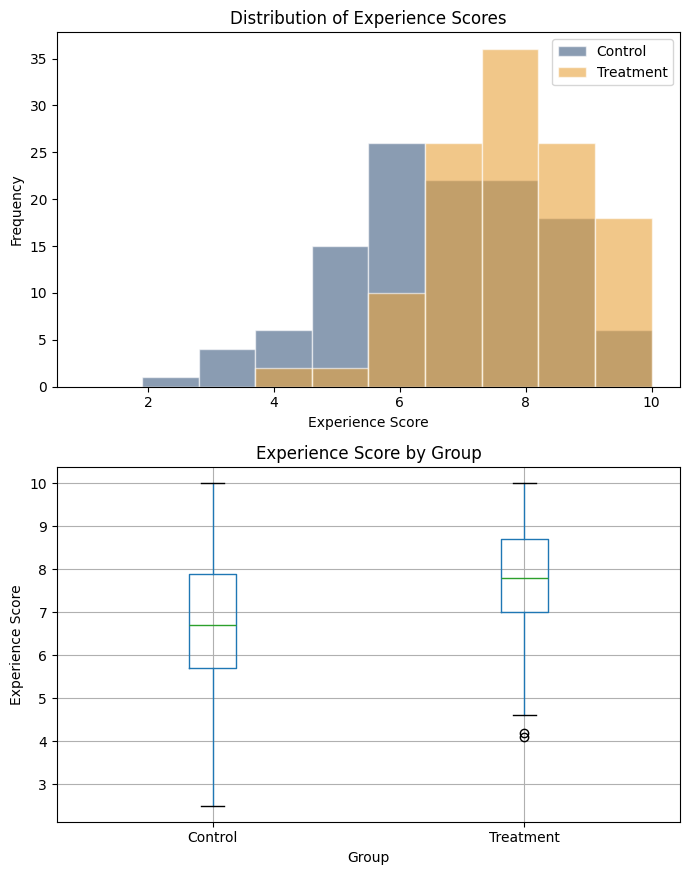

Control: median 6.70, IQR 2.20, share scoring 8+: 24.2%
Treatment: median 7.80, IQR 1.70, share scoring 8+: 45.0%


In [11]:
fig, ax = plt.subplots(2, 1, figsize=(7, 9))
bins = np.linspace(1, 10, 11)
ax[0].hist(
    control_s,
    bins=bins,
    alpha=0.6,
    label="Control",
    color="#3D5A80",
    edgecolor="white",
)
ax[0].hist(
    treatment_s,
    bins=bins,
    alpha=0.6,
    label="Treatment",
    color="#E9A23B",
    edgecolor="white",
)
ax[0].set_xlabel("Experience Score")
ax[0].set_ylabel("Frequency")
ax[0].set_title("Distribution of Experience Scores")
ax[0].legend()
practice.boxplot(
    column="Experience_Score", by="Group", ax=ax[1]
)
ax[1].set_xlabel("Group")
ax[1].set_ylabel("Experience Score")
ax[1].set_title("Experience Score by Group")
plt.suptitle("")
plt.tight_layout()
plt.show()

for g, sc in [
    ("Control", control_s),
    ("Treatment", treatment_s),
]:
    q1, q3 = sc.quantile([0.25, 0.75])
    print(
        f"{g}: median {sc.median():.2f}, IQR "
        f"{q3 - q1:.2f}, share scoring 8+: "
        f"{(sc >= 8).mean():.1%}"
    )

### Model interpretation (practice data)

**Histogram.** Reminder patients' scores cluster toward the top of the scale: 45% scored 8 or higher versus 24% of standard-service patients, who are more spread out with more low scores (14% at 5 or below vs. 3%). The distributions overlap, so not every reminder patient rated their experience higher, but the Treatment distribution has shifted right.

**Box plot.** The Treatment median (7.80) is above the Control median (6.70), and its box is narrower (IQR 1.70 vs. 2.20), so experience is more consistent with reminders. Control shows no outliers; Treatment shows outliers at 4.1, 4.2, likely patients who had an unusually poor experience, worth following up rather than deleting. Both charts support the t-test result.

### Your turn

Your answer must:
- ☐ Produce both charts, labeled (axes, title, legend on the histogram)
- ☐ **Histogram:** where scores concentrate for each group; which group has more high and low scores; how the distributions differ
- ☐ **Box plot:** which median is higher (approximate values), which group is more variable (box and whiskers), and any outliers and what they might represent
- ☐ Connect the patterns to your program's effect

## Task 7: Recommendation memo (10 points)

**What the task asks:** a 1–2 page memo in Markdown cells with a header (To/From/Date/Subject), a clear YES or NO, key findings with your numbers, a cost-benefit analysis, a recommendation, and limitations.

### How to solve it

1. **Decision first:** YES or NO in the first sentence, with the main reason.
2. **Key findings:** reuse your numbers from Tasks 2–5; don't introduce new ones.
3. **Cost-benefit:** do the math explicitly, and test the decision at the **low end** of the confidence interval as well as the mean.
4. **Recommendation:** restate, support with evidence, then give conditions for implementation.
5. **Limitations:** assumptions (persistence, scaling, who was in the pilot), risks, and the extra data you'd want.

### Worked cost-benefit (practice data)

In [12]:
cost = 15  # one-time setup per patient
gain = treatment_y.mean() - control_y.mean()
low = gain - 1.97 * se_diff
print(
    f"Monthly gain per patient: ${gain:,.2f} (low end of "
    f"95% CI: ${low:,.2f})"
)
print(
    f"Months to recover the ${cost} cost: "
    f"{cost / gain:.2f} (low end: {cost / low:.2f})"
)
print(
    "First-year net gain for 1,000 patients, if it "
    f"persists: ${1000 * (12 * gain - cost):,.0f}"
)

Monthly gain per patient: $17.22 (low end of 95% CI: $13.18)
Months to recover the $15 cost: 0.87 (low end: 1.14)
First-year net gain for 1,000 patients, if it persists: $191,585


### Model memo (practice data)

**TO:** VP of Pharmacy Operations  **FROM:** Analyst  **DATE:** [date]  **SUBJECT:** Expanding the Refill-Reminder Program

**Executive summary.** **YES. Expand text refill reminders to all patients with recurring prescriptions.** The $15 setup cost is recovered in under a month through higher refill revenue, and patient experience improves.

**Key findings.** Experience scores rose from 6.68 to 7.76 (t = -5.8488, p < 0.0001; d = 0.76). Monthly refill value rose from $80.37 to $97.59, a difference of $17.22; the 95% intervals [$77.34, $83.40] and [$94.88, $100.29] do not overlap. The regression (R² = 0.47) shows both experience (β = $6.19) and the program itself (β = $10.51) independently raise refill value.

**Cost-benefit analysis.** We spend $15 once and gain about $17.22 per patient per month: payback in **0.87 months**, or 1.14 months at the low end of the interval. For 1,000 patients, the first-year net gain is about **$191,585.00**, if the effect persists.

**Recommendation.** Roll the program out chain-wide, starting with high-volume stores, and track refill adherence and opt-out rates monthly.

**Limitations.** The pilot measured one month of refills; we assume the effect lasts and that pilot patients resemble the wider patient base. Text fatigue could reduce the effect over time. Data on medication adherence, opt-outs, and health outcomes would strengthen the case.

### Your turn: track-specific requirements

**Business:** cost is $50 per customer. Calculate the monthly spending gain, the payback ("We spend $50 and gain $__ per month"), and optionally the annual impact for, say, 1,000 new customers. State YES or NO on expanding to all new customers.

**Healthcare:** *you* estimate implementation costs (app licensing, staff training, IT support), so state and justify your assumptions. Calculate the savings per patient, annual savings for an assumed number of surgical patients, and the break-even number of patients (implementation cost ÷ savings per patient). Weigh patient experience and safety alongside cost.

**Public Administration:** cost is $5,000 per participant. Calculate the monthly and annual income increase, the payback in months ($5,000 ÷ monthly increase), and the annual ROI (annual increase ÷ $5,000 × 100). Estimate the share of each group earning above $3,200 and how many more participants reach self-sufficiency. Give your recommendation, primary reason, 2–3 limitations, and the data that would strengthen it.

**Every memo:**
- ☐ Header (To / From / Date / Subject), in Markdown cells
- ☐ YES or NO in the first sentence, with the main reason
- ☐ Specific numbers from Tasks 2–5 (t, p, means, difference, CI overlap, both coefficients, R²)
- ☐ Cost-benefit math shown, ideally tested at the low end of the CI
- ☐ Implementation considerations, limitations, and additional data needed

---
## The formula behind every full-credit answer

**Number → decision → plain English → practical meaning → limitation.**

Before you submit: run **Runtime → Restart and run all** in your own notebook to make sure every cell runs without errors.